# Practice 2 — Challenge A (cyber): R2 draft

**Role:** R2 — Classification lead  
**Scope:** P2.4 (baselines and KNN, cyber), P2.5 (probabilistic evaluation and the rare class), cyber dry-run submission file (P2.6).

> Draft notebook. Its sections are copied unchanged into `notebooks/P2_cyber.ipynb` by R5.

In [1]:
PROJECT_RANDOM_STATE = 2627
print("PROJECT_RANDOM_STATE =", PROJECT_RANDOM_STATE)

PROJECT_RANDOM_STATE = 2627


## 0. Setup

In [2]:
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, brier_score_loss, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, f1_score,
                             precision_score, recall_score, roc_auc_score, RocCurveDisplay)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.model_selection import cross_validate

## 1. Data

Grouping metadata (`feature_group`) and `row_id` are loaded but are **never** estimator inputs.

In [3]:
DATA_DIR = "../../datos/cyber/"

dev = pd.read_csv(DATA_DIR + "cyber_development.csv")
groups = pd.read_csv(DATA_DIR + "cyber_groups.csv")
with open(DATA_DIR + "cyber_class_codes.json") as fh:
    CLASS_NAMES = {int(k): v for k, v in json.load(fh).items()}

assert (dev["row_id"] == groups["row_id"]).all()

CYBER_NOMINAL = ["proto", "service", "conn_state"]
CYBER_NUMERIC = ["duration", "src_bytes", "dst_bytes", "missed_bytes",
           "src_pkts", "src_ip_bytes", "dst_pkts", "dst_ip_bytes"]
FEATURES = CYBER_NOMINAL + CYBER_NUMERIC

X = dev[FEATURES]
y = dev["attack_code"]
print(X.shape, y.shape)

(34928, 11) (34928,)


In [4]:
support = (y.value_counts().sort_index()
           .rename(index=CLASS_NAMES).rename("support").to_frame())
support

,support
attack_code,
backdoor,1573
ddos,4800
dos,4800
injection,4800
mitm,805
normal,4800
password,4800
ransomware,208
scanning,3542


The classes are imbalanced: ransomware has only **208** rows (0.6 %) and mitm 805,
versus 4,800 for most classes. That is why we stratify the folds, use macro F1 as the primary metric,
and always report ransomware figures beside its support.

## 2. Preprocessing

Preprocessing block published by R1 (make_cyber_preprocessor), fitted inside each fold through the Pipeline.

In [5]:
def make_cyber_preprocessor():
    numeric_steps = Pipeline([
        ("log1p", FunctionTransformer(np.log1p)),
        ("scale", StandardScaler())
    ])

    nominal_steps = OneHotEncoder(handle_unknown="ignore")

    preprocessor = ColumnTransformer([
        ("nominal", nominal_steps, CYBER_NOMINAL),
        ("numeric", numeric_steps, CYBER_NUMERIC),
    ])
    return preprocessor

## 3. Folds

Canonical fold assignment (cyber_folds.csv), adopted for every scored result.

In [6]:
canonical = pd.read_csv("../../datos/cyber/cyber_folds.csv")
assert (canonical["row_id"] == dev["row_id"]).all()   # same row order as our data

fold_id = canonical["fold_id"].to_numpy()

folds = []
for f in range(5):
    train_idx = np.where(fold_id != f)[0]   # rows NOT in fold f -> training
    val_idx = np.where(fold_id == f)[0]     # rows in fold f -> validation
    folds.append((train_idx, val_idx))




## 4. P2.4 — Baseline: `DummyClassifier(strategy="most_frequent")`

In [7]:
dummy = DummyClassifier(strategy="most_frequent")

scores = cross_validate(dummy, X, y, cv=folds, scoring=["f1_macro", "f1_weighted", "accuracy"])


print("Macro F1 per fold:", scores["test_f1_macro"])
print("Macro F1 mean:", scores["test_f1_macro"].mean())
print("Accuracy mean:", scores["test_accuracy"].mean())
print("Weighted F1 mean:", scores["test_f1_weighted"].mean())
print("Fit time per fold (s):", scores["fit_time"].round(3))

Macro F1 per fold: [0.0241631  0.0241631  0.02416614 0.0241631  0.02416614]
Macro F1 mean: 0.024164317449898203
Accuracy mean: 0.13742556183027677
Weighted F1 mean: 0.03320794916157151
Fit time per fold (s): [0.065 0.008 0.01  0.009 0.009]


The baseline always predicts the most frequent class and ignores the features.
Its accuracy is about 0.14, but its macro F1 is only about 0.02: it gets one class partly right and
the other nine completely wrong. Macro F1 averages the F1 of the ten classes with equal weight, so
it exposes a model that ignores most classes, while accuracy hides it. Any useful model must clearly
beat this floor.

## 5. P2.4 — KNN over a grid of KNN values

Notation: **K = 5** is the number of folds; **KNN** is the number of neighbours.

KNN classifies a flow by the distance to its nearest neighbours, so every
feature's scale directly sets its weight in that distance. The numeric predictors span very
different ranges: the median duration is about 0.05 s, while src_bytes reaches about 1.4 × 10⁹.
Without scaling, the byte counts would dominate the distance and the other features would be
ignored. We therefore apply log1p to the eight numeric predictors (it compresses many orders of
magnitude and is defined at zero, which is common here) and then standardise them. The three
nominal predictors are one-hot encoded. All of it is inside a Pipeline, so it is fitted on the
training part of each fold only.

In [8]:
KNN_GRID = [1, 3, 5, 7, 9, 15, 21, 31, 51]

knn_means = []
knn_stds = []

for n in KNN_GRID:
    model = Pipeline([
        ("prep", make_cyber_preprocessor()),
        ("knn", KNeighborsClassifier(n_neighbors=n)),
    ])
    scores = cross_validate(model, X, y, cv=folds, scoring="f1_macro")
    f1_folds = scores["test_score"]

    knn_means.append(f1_folds.mean())
    knn_stds.append(f1_folds.std())
    print("KNN =", n, "-> macro F1 mean:", round(f1_folds.mean(), 4), " std:", round(f1_folds.std(), 4))

KNN = 1 -> macro F1 mean: 0.9437  std: 0.003
KNN = 3 -> macro F1 mean: 0.9456  std: 0.0023
KNN = 5 -> macro F1 mean: 0.9442  std: 0.0044
KNN = 7 -> macro F1 mean: 0.9436  std: 0.0039
KNN = 9 -> macro F1 mean: 0.9413  std: 0.0044
KNN = 15 -> macro F1 mean: 0.9385  std: 0.0039
KNN = 21 -> macro F1 mean: 0.9288  std: 0.0051
KNN = 31 -> macro F1 mean: 0.9215  std: 0.0051
KNN = 51 -> macro F1 mean: 0.9171  std: 0.006


### KNN curve (mean ± fold spread)

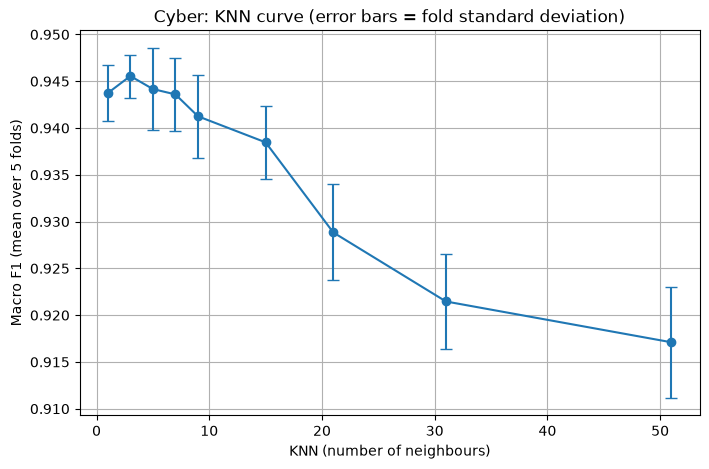

In [9]:
plt.figure(figsize=(8, 5))
plt.errorbar(KNN_GRID, knn_means, yerr=knn_stds, marker="o", capsize=4)
plt.xlabel("KNN (number of neighbours)")
plt.ylabel("Macro F1 (mean over 5 folds)")
plt.title("Cyber: KNN curve (error bars = fold standard deviation)")
plt.grid(True)
plt.show()

Macro F1 is almost flat for KNN = 1 to 7 (0.9436–0.9456): the differences between
these values are about the same size as the fold-to-fold standard deviation (0.002–0.004), so on these
folds they are practically tied. 

From KNN ≈ 9 the curve falls steadily, down to 0.917 at KNN = 51.

A larger neighbourhood averages over more distant flows, so small classes such as ransomware (208 rows)
and mitm (805 rows) are increasingly outvoted by the large classes, and macro F1, which weights every
class equally, drops. 

We choose KNN = 3, the highest mean, while noting that KNN = 1–7 are
equivalent within the observed fold variability. All KNN values remain far above the
most-frequent baseline (macro F1 ≈ 0.02).

## 6. P2.4 — Full metric set for the chosen KNN

Macro F1 (primary), weighted F1, accuracy; per-class precision, recall and F1 **beside their support**; confusion matrix with the semantic class names.

In [10]:
best_knn = Pipeline([
    ("prep", make_cyber_preprocessor()),
    ("knn", KNeighborsClassifier(n_neighbors=3)),
])

scores = cross_validate(best_knn, X, y, cv=folds,
                        scoring=["f1_macro", "f1_weighted", "accuracy"])

print("Macro F1    per fold:", scores["test_f1_macro"].round(4), " mean:", scores["test_f1_macro"].mean().round(4))
print("Weighted F1 per fold:", scores["test_f1_weighted"].round(4), " mean:", scores["test_f1_weighted"].mean().round(4))
print("Accuracy    per fold:", scores["test_accuracy"].round(4), " mean:", scores["test_accuracy"].mean().round(4))
print("Fit time per fold (s):", scores["fit_time"].round(3))

Macro F1    per fold: [0.9436 0.9473 0.949  0.9428 0.9451]  mean: 0.9456
Weighted F1 per fold: [0.9619 0.9637 0.9645 0.9592 0.9624]  mean: 0.9623
Accuracy    per fold: [0.9616 0.9632 0.9645 0.9591 0.9619]  mean: 0.9621
Fit time per fold (s): [0.093 0.083 0.085 0.075 0.081]


In [11]:
from sklearn.model_selection import cross_val_predict

y_pred = cross_val_predict(best_knn, X, y, cv=folds)

class_names = [CLASS_NAMES[i] for i in range(10)]
print(classification_report(y, y_pred, target_names=class_names, digits=3))

              precision    recall  f1-score   support

    backdoor      0.989     0.994     0.991      1573
        ddos      0.969     0.966     0.968      4800
         dos      0.956     0.947     0.952      4800
   injection      0.962     0.958     0.960      4800
        mitm      0.721     0.795     0.756       805
      normal      0.984     0.976     0.980      4800
    password      0.992     0.980     0.986      4800
  ransomware      0.951     0.942     0.947       208
    scanning      0.958     0.958     0.958      3542
         xss      0.949     0.966     0.958      4800

    accuracy                          0.962     34928
   macro avg      0.943     0.948     0.946     34928
weighted avg      0.963     0.962     0.962     34928



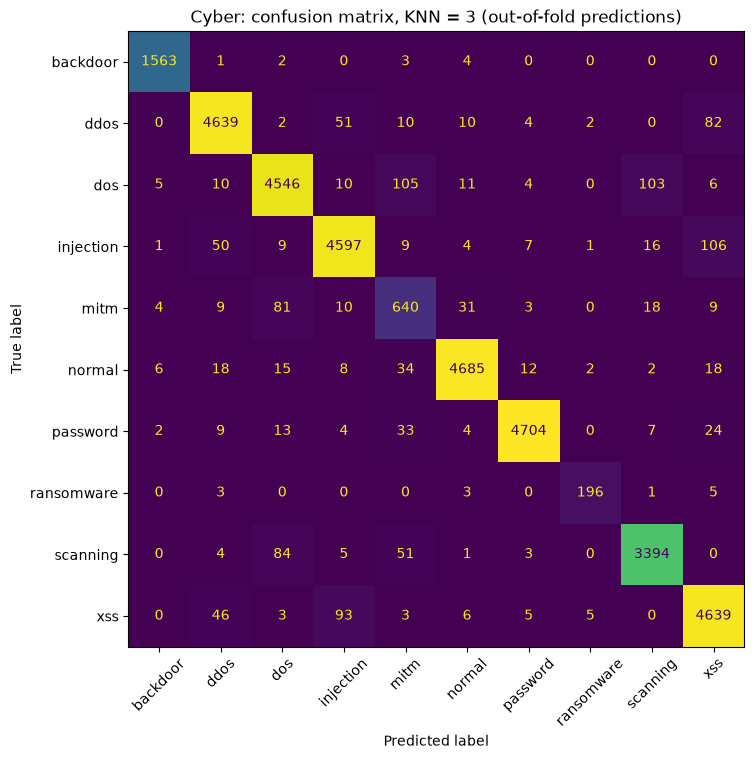

In [12]:
fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay.from_predictions(y, y_pred, display_labels=class_names,
                                        xticks_rotation=45, ax=ax, colorbar=False)
ax.set_title("Cyber: confusion matrix, KNN = 3 (out-of-fold predictions)")
plt.show()

 With KNN = 3, macro F1 is 0.946 (fold range 0.943–0.949), weighted F1 0.962 and
accuracy 0.962. Weighted F1 is higher than macro F1 because the large classes are classified very well,
while the weakest class, mitm (F1 0.756, support 805), counts for little in a weighted average but
for a full tenth of the macro average.

The confusions are concentrated in a few pairs:
- injection / xss (106 and 93 errors respectively): both are web attacks over HTTP; what distinguishes them is
  the content of the request, which is not in our features. At flow level (protocol, service,
  connection state, bytes, packets, duration) they look almost the same.
- dos / scanning / mitm (e.g. 105 dos predicted as mitm, 103 dos as scanning, 81 mitm as dos):
  all three produce many short connections with few packets, so their flows lie close together.
- ddos / xss (82 and 46 respectively): again short web-like flows.

This tells us that the feature space only describes how traffic flows, not what it carries: classes
that differ mainly in payload or intent overlap, and the small class mitm is surrounded by larger ones
and loses most. Ransomware reaches F1 0.947, but with a support of only 208 each error moves
its recall by about 0.5 points, so its per-class figures are much less stable than those of the
large classes.

## 7. P2.5 — Ransomware one-vs-rest: ROC, AUC and Brier

Out-of-fold `predict_proba`; always report ransomware figures beside its support (208).

In [13]:
proba = cross_val_predict(best_knn, X, y, cv=folds, method="predict_proba")

p_ransom = proba[:, 7]      # column 7 = probability of ransomware (code 7)
is_ransom = (y == 7)        # True if the row really is ransomware

print("Ransomware support:", is_ransom.sum())
print("Distinct values of p(ransomware):", np.unique(p_ransom).round(3).tolist())
print("AUC  :", round(roc_auc_score(is_ransom, p_ransom), 4))
print("Brier:", round(brier_score_loss(is_ransom, p_ransom), 5))

Ransomware support: 208
Distinct values of p(ransomware): [0.0, 0.333, 0.667, 1.0]
AUC  : 0.9783
Brier: 0.00059


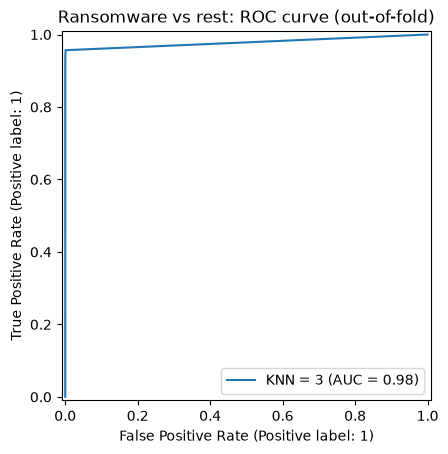

In [14]:
RocCurveDisplay.from_predictions(is_ransom, p_ransom, name="KNN = 3")
plt.title("Ransomware vs rest: ROC curve (out-of-fold)")
plt.show()

Ransomware (support 208) is separated very well from the rest: AUC = 0.978,
Brier = 0.00059 (about ten times lower than the 0.006 of a model that always says p = 0).
With KNN = 3, p(ransomware) only takes four values (0, 1/3, 2/3, 1), so the ROC curve has just
four points and is very coarse.

## 8. P2.5 — Course-fixed rare-class decision rule

For a fixed τ: if p(ransomware) ≥ τ predict ransomware, otherwise predict the highest-probability class among the other nine. Thresholds: τ ∈ {0.05, 0.10, 0.20, 0.35, 0.50}, plus the ordinary ten-class argmax as a separate baseline row. No threshold search.

In [15]:
TAUS = [0.05, 0.10, 0.20, 0.35, 0.50]
y_true = y.to_numpy()

# Normal prediction: the class with the highest probability (out of 10)
argmax_pred = proba.argmax(axis=1)

# Best class among the OTHER nine: hide ransomware (column 7) and take the max again
proba_others = proba.copy()
proba_others[:, 7] = -1
best_other = proba_others.argmax(axis=1)


def ransomware_row(name, pred):
    tp = ((pred == 7) & (y_true == 7)).sum()          # real ransomware caught
    false_alarms = ((pred == 7) & (y_true != 7)).sum() # said ransomware but it was not
    return {
        "rule": name,
        "recall": round(tp / 208, 3),
        "precision": round(tp / (tp + false_alarms), 3),
        "caught (of 208)": tp,
        "false alarms": false_alarms,
        "other predictions changed": (pred != argmax_pred).sum(),
        "macro F1": round(f1_score(y_true, pred, average="macro"), 4),
    }


rows = [ransomware_row("10-class argmax (baseline)", argmax_pred)]
for tau in TAUS:
    pred = np.where(p_ransom >= tau, 7, best_other)
    rows.append(ransomware_row("tau = " + str(tau), pred))

pd.DataFrame(rows)

,rule,recall,precision,caught (of 208),false alarms,other predictions changed,macro F1
0,10-class argmax (baseline),0.942,0.951,196,10,0,0.9455
1,tau = 0.05,0.957,0.840,199,38,31,0.9403
2,tau = 0.1,0.957,0.840,199,38,31,0.9403
3,tau = 0.2,0.957,0.840,199,38,31,0.9403
4,tau = 0.35,0.942,0.951,196,10,0,0.9455
5,tau = 0.5,0.942,0.951,196,10,0,0.9455


Because KNN = 3 gives only four probability values, the five thresholds collapse
into two distinct rules:
- τ = 0.05, 0.10, 0.20 all mean "predict ransomware if at least 1 of the 3 neighbours is ransomware"
  (p ≥ 1/3);
- τ = 0.35, 0.50 mean "at least 2 of 3" (p ≥ 2/3), which is what the ordinary ten-class argmax already
  does, so they reproduce the baseline row exactly.

Operational argument for lowering τ. Going from argmax to τ ≤ 1/3 catches 3 more ransomware flows
(196 → 199 of 208; recall 0.942 → 0.957). A missed ransomware flow can mean encrypted systems, so an
operator may value every extra detection highly.

What it costs. False alarms rise from 10 to 38: about 9 extra alarms for each extra detection, and
each one must be triaged by an analyst. Precision drops from 0.951 to 0.840. The other nine classes also pay: 28 of their flows are now relabelled as ransomware, 18 of which were previously classified correctly (mostly xss and normal), so their recall falls, and overall macro F1 goes
from 0.9455 to 0.9403.

This is a fixed probability-and-decision exercise: no threshold is selected here, and none is carried into
model selection. The project's primary metric remains macro F1 with ordinary argmax prediction.

## 9. P2.6 — Dry-run submission file (cyber)

Build `entregas_prueba/cyber_dry_run.csv` (`row_id,attack_code`) from a development subset, and save that subset's features so R5 can run `validate_submission.py`.

In [16]:
train_idx = folds[0][0]
val_idx = folds[0][1]

# Train KNN = 3 on the training part of fold 0
best_knn.fit(X.iloc[train_idx], y.iloc[train_idx])

# The validation part of fold 0 plays the role of the "final test"
subset = dev.iloc[val_idx]

# File 1: the features of the subset (row_id + the 11 features, NO target)
subset[["row_id"] + FEATURES].to_csv("../../entregas_prueba/cyber_dry_run_features.csv", index=False)

# File 2: our predictions in the exact submission format
submission = pd.DataFrame({
    "row_id": subset["row_id"],
    "attack_code": best_knn.predict(subset[FEATURES]),
})
submission.to_csv("../../entregas_prueba/cyber_dry_run.csv", index=False)

print(submission.shape)
submission.head()

(6986, 2)


,row_id,attack_code
1,C00001,9
4,C00004,1
17,C00017,5
20,C00020,2
22,C00022,6


In [17]:
!python ../../herramientas/validate_submission.py cyber ../../entregas_prueba/cyber_dry_run.csv ../../entregas_prueba/cyber_dry_run_features.csv ../../datos/cyber/cyber_class_codes.json

valid
